In [46]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from ipynb.fs.full.data import returns

# current features
- Daily Returns
- 20 day Sign Persistance
- 20 day Rolling Volitilty
- Moving average Trend


In [47]:
nifty_index=pd.read_csv('nifty_index.csv')


In [48]:
daily_returns=returns(nifty_index)

In [49]:
def sign_persistence(daily_returns):
    signs = np.sign(daily_returns)
    same_sign = signs.eq(signs.shift(1))
    valid_pairs = (
        signs.notna() & signs.shift(1).notna() &
        signs.ne(0) & signs.shift(1).ne(0)
    )
    window=20

    matches = (same_sign & valid_pairs).rolling(window).sum()
    valid_counts = valid_pairs.rolling(window).sum()

    sign_persistence = matches / valid_counts.replace(0, np.nan)
    return sign_persistence

sign_persistence=sign_persistence(daily_returns)

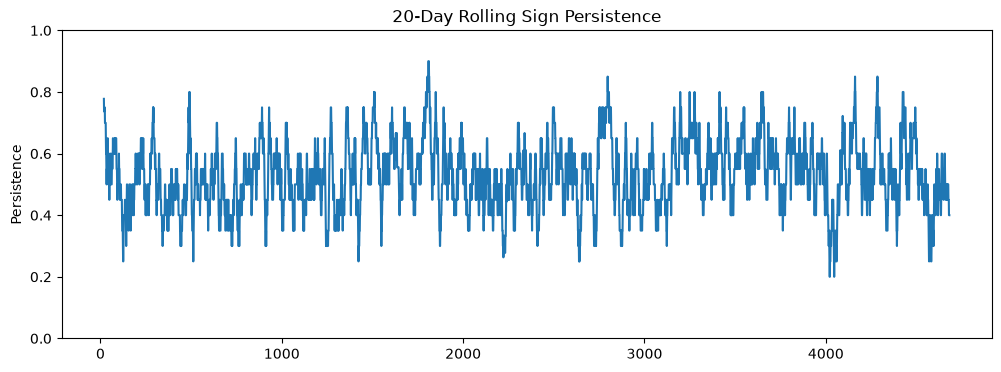

In [50]:
window=20
plt.figure(figsize=(12, 4))
plt.plot(sign_persistence)
plt.title(f"{window}-Day Rolling Sign Persistence")
plt.ylabel("Persistence")
plt.ylim(0, 1)
plt.show()

In [51]:
def rolling_volatility(daily_returns):
    return daily_returns.rolling(window=20).std()

rolling_volatility=rolling_volatility(daily_returns)

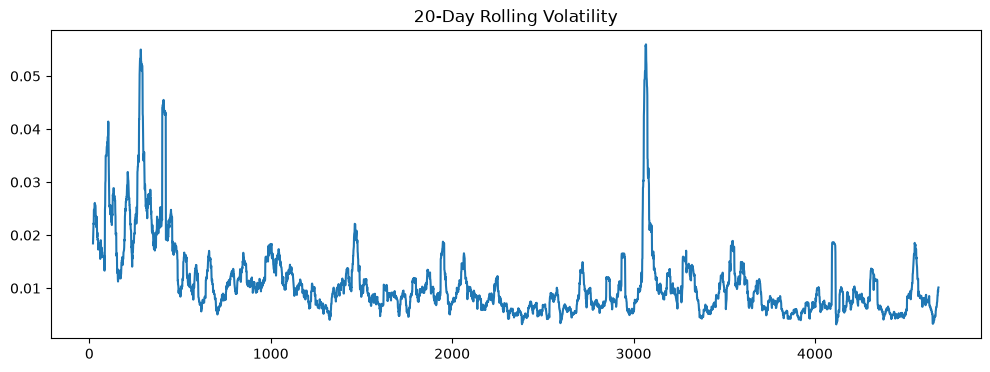

In [52]:
plt.figure(figsize=(12, 4))

plt.plot(rolling_volatility)
plt.title("20-Day Rolling Volatility")
plt.show()

In [53]:
def trend(nifty_index):
    SMA_20 = nifty_index["Close"].rolling(window=20).mean()
    SMA_50 = nifty_index["Close"].rolling(window=50).mean()

    trend = (SMA_20 - SMA_50) / SMA_50
    return trend

trend=trend(nifty_index)

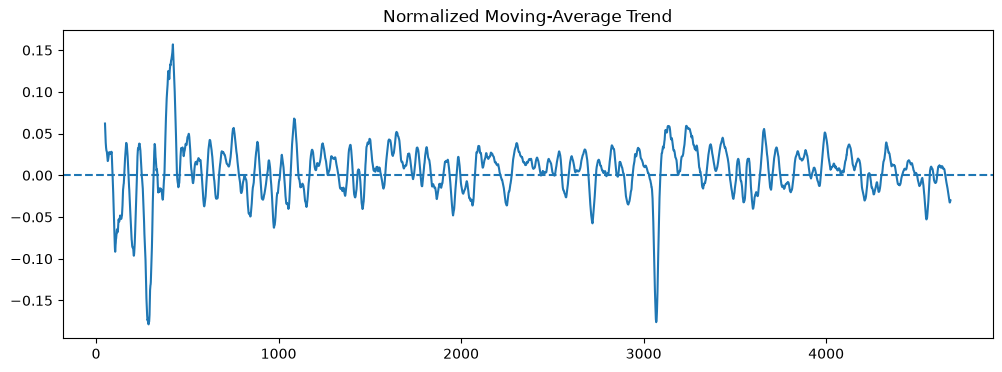

In [54]:
plt.figure(figsize=(12, 4))
plt.plot(trend)
plt.title("Normalized Moving-Average Trend")
plt.axhline(0, linestyle="--")
plt.show()

In [55]:
features=pd.concat([daily_returns,sign_persistence,rolling_volatility,trend],axis=1)
features=features.dropna(axis=0)
features.columns=["daily_returns","sign_persistence","rolling_volatility","trend"]
features

,daily_returns,sign_persistence,rolling_volatility,trend
49,-0.005853,0.45,0.017276,0.062023
50,-0.014145,0.50,0.017475,0.055358
51,0.003035,0.50,0.017429,0.048744
52,0.022743,0.55,0.018264,0.043876
53,0.017743,0.60,0.018544,0.039046
...,...,...,...,...
4677,-0.006976,0.45,0.008648,-0.032535
4678,0.016035,0.45,0.009572,-0.032605
4679,-0.004368,0.40,0.009279,-0.031892
4680,0.016561,0.40,0.010026,-0.031031


In [56]:
split_idx = int(len(features) * 0.8)
train_df=features.iloc[:split_idx]
test_df=features.iloc[split_idx:]
print(len(train_df))
print(len(test_df))


3706
927


In [57]:

means=train_df.mean()
%store means

standard_deviations=train_df.std()
%store standard_deviations

Stored 'means' (Series)
Stored 'standard_deviations' (Series)


In [58]:
train_df=train_df-means
train_df=train_df/standard_deviations
train_df

,daily_returns,sign_persistence,rolling_volatility,trend
49,-0.455275,-0.743581,0.769154,1.620019
50,-1.058761,-0.278561,0.796237,1.430789
51,0.191674,-0.278561,0.790002,1.243011
52,1.626112,0.186459,0.903506,1.104814
53,1.262184,0.651479,0.941577,0.967679
...,...,...,...,...
3750,-0.234156,-0.743581,-0.532896,-0.225355
3751,-0.566055,-0.278561,-0.526761,-0.278562
3752,0.955982,-0.278561,-0.429331,-0.318966
3753,-0.781349,-0.743581,-0.419502,-0.369747


In [59]:
test_df=test_df-means
test_df=test_df/standard_deviations
test_df.to_csv('test_df.csv')
test_df


,daily_returns,sign_persistence,rolling_volatility,trend
3755,-0.181754,-0.278561,-0.484691,-0.457656
3756,0.371808,-0.743581,-0.485161,-0.478946
3757,-0.279530,-0.743581,-0.522820,-0.512919
3758,0.615231,-0.743581,-0.477979,-0.534109
3759,0.422499,-0.743581,-0.499678,-0.536985
...,...,...,...,...
4677,-0.536967,-0.743581,-0.403724,-1.064640
4678,1.137861,-0.743581,-0.278174,-1.066627
4679,-0.347159,-1.208601,-0.318005,-1.046385
4680,1.176121,-1.208601,-0.216457,-1.021933


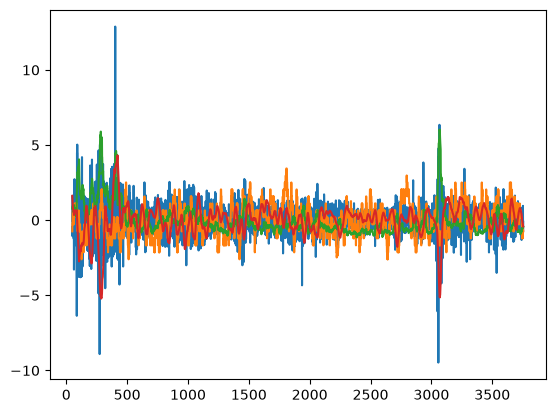

In [60]:
plt.plot(train_df)

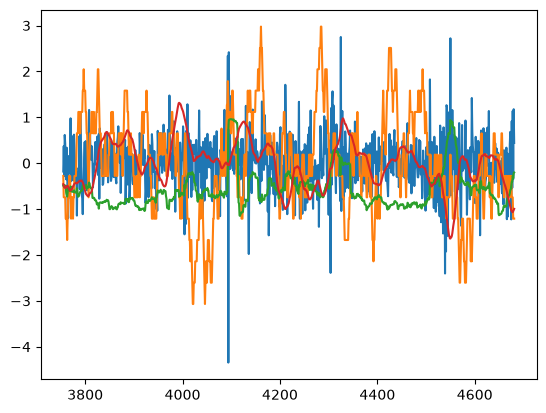

In [61]:
plt.plot(test_df)

In [62]:
train_df['trend'].corr(train_df['rolling_volatility'])


np.float64(-0.46429749500191936)

In [63]:
train_df.to_csv('train_df.csv')
train_df.to_csv('test_df.csv')